## Beta Diversity and Community Similarity
#### Pedro Palacios

In [59]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [60]:
# Load the data
asv_counts = pd.read_csv("/Users/peterpalaciosjr/Data_Mining_Fall_2026/projects/soilmicrobiomeproject_bioinformatics/data/ASV_counts_25_samples.csv")

asv_sequences = pd.read_csv("/Users/peterpalaciosjr/Data_Mining_Fall_2026/projects/soilmicrobiomeproject_bioinformatics/data/ASV_sequences_with_taxonomy.csv")

sample_metadata = pd.read_csv("/Users/peterpalaciosjr/Data_Mining_Fall_2026/projects/soilmicrobiomeproject_bioinformatics/data/sample_metadata.csv")

In [61]:
from scipy.spatial.distance import pdist, squareform
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns

# ASV-by-park matrix
asv_matrix = asv_counts.set_index("ASV")

In [62]:
top_asvs = asv_matrix.sum(axis=1).sort_values(ascending=False).head(50).index
asv_matrix = asv_matrix.loc[top_asvs]

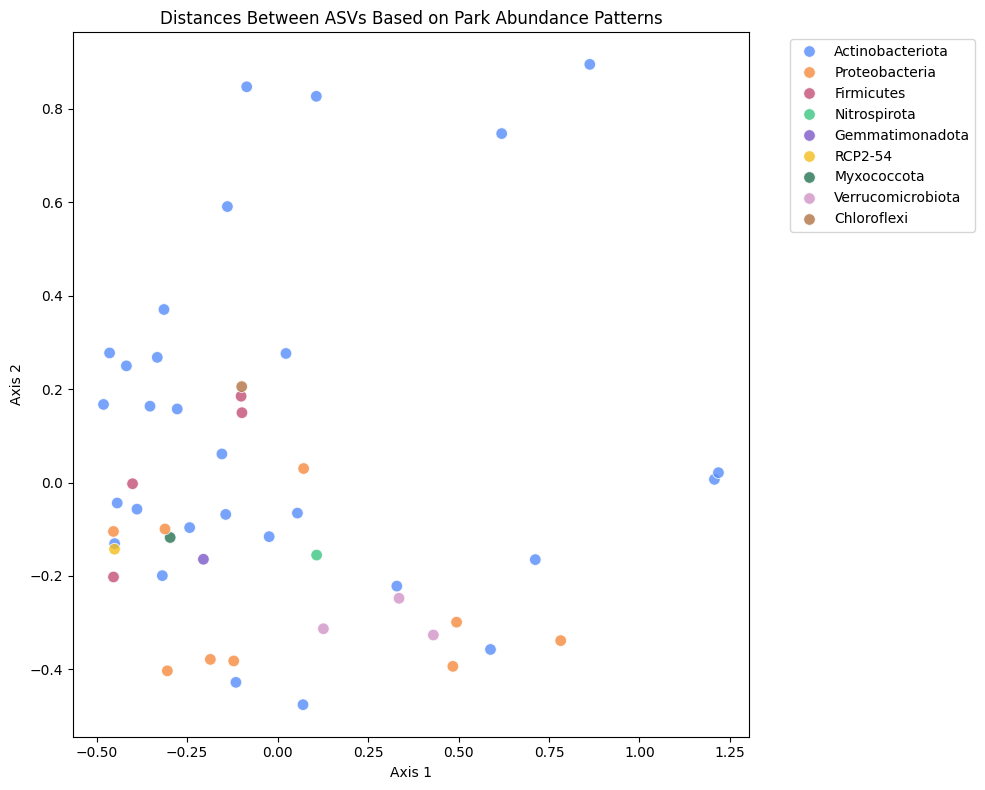

In [63]:
# Raw ASV count matrix
asv_matrix = asv_counts.set_index("ASV")
asv_matrix = asv_matrix.apply(pd.to_numeric, errors="coerce").fillna(0)

# Remove ASVs with very low total abundance
min_total_count = 10
asv_matrix_filtered = asv_matrix[asv_matrix.sum(axis=1) >= min_total_count]

# Remove ASVs found in too few samples
min_samples_present = 2
asv_matrix_filtered = asv_matrix_filtered[
    (asv_matrix_filtered > 0).sum(axis=1) >= min_samples_present
]

# Optional: keep most abundant ASVs for speed and readability
top_n = 50
top_asvs = asv_matrix_filtered.sum(axis=1).sort_values(ascending=False).head(top_n).index
asv_matrix_top = asv_matrix_filtered.loc[top_asvs]

# Normalize each sample/park column to relative abundance
asv_rel = asv_matrix_top.div(
    asv_matrix_top.sum(axis=0),
    axis=1
).fillna(0)

# Square-root transform relative abundances
# This reduces dominance of extremely abundant ASVs
X_asvs = np.sqrt(asv_rel)

# Bray-Curtis distances between ASVs
asv_dist = pdist(X_asvs, metric="braycurtis")

asv_dist_matrix = pd.DataFrame(
    squareform(asv_dist),
    index=X_asvs.index,
    columns=X_asvs.index
)

# PCoA-like visualization
pca = PCA(n_components=2)
coords = pca.fit_transform(asv_dist_matrix)

asv_plot = pd.DataFrame(
    coords,
    index=asv_dist_matrix.index,
    columns=["Axis 1", "Axis 2"]
).join(asv_taxonomy, how="left")

plt.figure(figsize=(10, 8))

sns.scatterplot(
    data=asv_plot,
    x="Axis 1",
    y="Axis 2",
    hue="Phylum",
    s=70,
    alpha=0.8
)

plt.title("Distances Between ASVs Based on Park Abundance Patterns")
plt.xlabel("Axis 1")
plt.ylabel("Axis 2")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [78]:
# ASV table: rows = ASVs, columns = samples
asv_matrix = asv_counts.set_index("ASV")
asv_matrix = asv_matrix.apply(pd.to_numeric, errors="coerce").fillna(0)
# Optional filtering to remove very rare ASVs
asv_matrix = asv_matrix[asv_matrix.sum(axis=1) >= 10]

# Convert to sample-by-ASV matrix
sample_matrix = asv_matrix.T

sample_matrix.head()

ASV,ASV1,ASV2,ASV3,ASV4,ASV5,ASV6,ASV7,ASV8,ASV9,ASV10,...,ASV28564,ASV28565,ASV28566,ASV28567,ASV28568,ASV28569,ASV28570,ASV28571,ASV28572,ASV28573
Loop1604-S1,2442,2337,511,1641,4048,1529,1592,773,1682,1653,...,0,0,0,0,0,0,0,0,0,0
Loop1604-S2,2316,2212,505,2033,4547,1740,1233,1154,1643,1804,...,0,0,0,0,0,0,0,0,0,0
Loop1604-S3,3926,3673,578,1474,3255,1325,1255,862,3398,1279,...,0,0,0,0,0,0,0,0,0,0
Loop1604-S4,2688,2415,425,1074,2881,1444,1350,830,2170,1227,...,0,0,0,0,0,0,0,0,0,0
Loop1604-S5,2428,2299,562,2473,6875,2550,1093,1540,1771,2578,...,0,0,0,0,0,0,0,0,0,0


In [65]:
sample_rel = sample_matrix.div(
    sample_matrix.sum(axis=1),
    axis=0
).fillna(0)

In [66]:
bc_dist = pdist(sample_rel, metric="braycurtis")

bc_dist_matrix = pd.DataFrame(
    squareform(bc_dist),
    index=sample_rel.index,
    columns=sample_rel.index
)

In [67]:
bc_sim_matrix = 1 - bc_dist_matrix # Converts the distances to similarity

In [83]:
sample_metadata = pd.DataFrame(index=sample_rel.index)
sample_metadata["Park"] = sample_metadata.index.to_series().str.replace(
    r"[-_]S\d+$",
    "",
    regex=True
)

sample_metadata.head()

,Park
Loop1604-S1,Loop1604
Loop1604-S2,Loop1604
Loop1604-S3,Loop1604
Loop1604-S4,Loop1604
Loop1604-S5,Loop1604


In [84]:
pairs = []

samples = bc_sim_matrix.index.to_list()

for i in range(len(samples)):
    for j in range(i + 1, len(samples)):
        sample1 = samples[i]
        sample2 = samples[j]

        park1 = sample_metadata.loc[sample1, "Park"]
        park2 = sample_metadata.loc[sample2, "Park"]

        pairs.append({
            "Sample1": sample1,
            "Sample2": sample2,
            "Park1": park1,
            "Park2": park2,
            "Similarity": bc_sim_matrix.loc[sample1, sample2],
            "Distance": bc_dist_matrix.loc[sample1, sample2],
            "Comparison": "Within park" if park1 == park2 else "Between park"
        })

pairwise_similarity = pd.DataFrame(pairs)

pairwise_similarity.head()

,Sample1,Sample2,Park1,Park2,Similarity,Distance,Comparison
0,Loop1604-S1,Loop1604-S2,Loop1604,Loop1604,0.809536,0.190464,Within park
1,Loop1604-S1,Loop1604-S3,Loop1604,Loop1604,0.756090,0.243910,Within park
2,Loop1604-S1,Loop1604-S4,Loop1604,Loop1604,0.770942,0.229058,Within park
3,Loop1604-S1,Loop1604-S5,Loop1604,Loop1604,0.728635,0.271365,Within park
4,Loop1604-S1,Eisenhower_1,Loop1604,Eisenhower_1,0.267769,0.732231,Between park


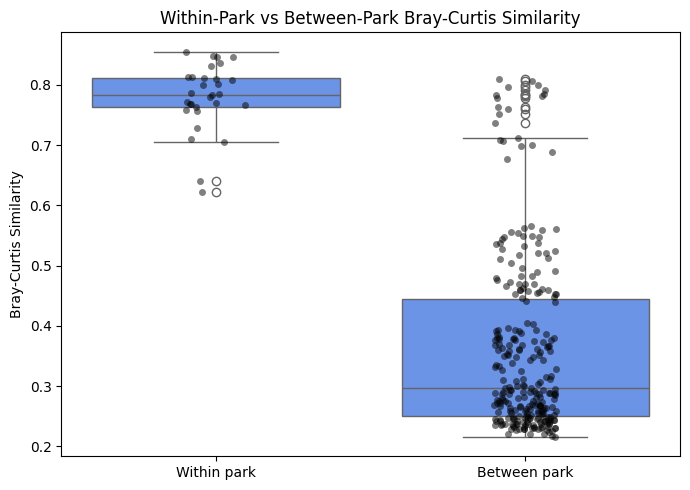

In [89]:
plt.figure(figsize=(7, 5))

sns.boxplot(
    data=pairwise_similarity,
    x="Comparison",
    y="Similarity"
)

sns.stripplot(
    data=pairwise_similarity,
    x="Comparison",
    y="Similarity",
    color="black",
    alpha=0.5,
    jitter=True
)

plt.title("Within-Park vs Between-Park Bray-Curtis Similarity")
plt.xlabel("")
plt.ylabel("Bray-Curtis Similarity")
plt.tight_layout()
plt.show()

In [90]:
from scipy.stats import mannwhitneyu

within_vals = pairwise_similarity.loc[
    pairwise_similarity["Comparison"] == "Within park",
    "Similarity"
]

between_vals = pairwise_similarity.loc[
    pairwise_similarity["Comparison"] == "Between park",
    "Similarity"
]

stat, p_value = mannwhitneyu(
    within_vals,
    between_vals,
    alternative="greater"
)

stat, p_value

(7907.0, 5.855126577887299e-18)